# PNR Waitlist Ticket Confirmation Prediction
## Exploratory Data Analysis & Model Training

**Objective:** Predict whether a waitlisted Indian Railways ticket will get confirmed (Yes/No) using Logistic Regression.

**Dataset:** [Indian Railway Ticket Confirmation (Kaggle)](https://www.kaggle.com/datasets/aaryananil/indian-railway-ticket-confirmation)

---

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)
import joblib
import os
import warnings
warnings.filterwarnings('ignore')

# Plot settings
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

print('All libraries imported successfully!')

All libraries imported successfully!


## 2. Load Dataset

In [2]:
# Load the dataset
df = pd.read_csv('../data/Railway Ticket Confirmation.csv')

print(f'Dataset Shape: {df.shape}')
print(f'Total Rows: {df.shape[0]:,}')
print(f'Total Columns: {df.shape[1]}')
print()
df.head()

Dataset Shape: (30000, 21)
Total Rows: 30,000
Total Columns: 21



,PNR Number,Train Number,Date of Journey,Class of Travel,Quota,Source Station,Destination Station,Booking Date,Current Status,Number of Passengers,...,Booking Channel,Travel Distance,Number of Stations,Travel Time,Train Type,Seat Availability,Special Considerations,Holiday or Peak Season,Waitlist Position,Confirmation Status
0,3746317213,13278,2025-12-15,Sleeper,Ladies,Station 22,Station 153,2025-09-04,Waitlisted,3,...,IRCTC Website,1338,12,22.3,Rajdhani,0,NaN,No,WL104,Not Confirmed
1,8479902459,42098,2025-12-10,3AC,Tatkal,Station 60,Station 180,2025-12-09,Waitlisted,2,...,IRCTC Website,121,13,2.0,Express,0,Yes,No,WL170,Not Confirmed
2,1958682846,23434,2025-07-09,Sleeper,Tatkal,Station 89,Station 160,2025-06-25,Waitlisted,1,...,Counter,1254,6,20.9,Shatabdi,0,NaN,No,WL167,Not Confirmed
3,9963334018,65302,2025-08-30,Sleeper,Tatkal,Station 4,Station 102,2025-08-17,Waitlisted,4,...,Mobile App,1578,13,26.3,Shatabdi,0,NaN,No,WL081,Not Confirmed
4,1136505587,22280,2025-02-23,2AC,Tatkal,Station 78,Station 187,2025-02-18,Waitlisted,4,...,Counter,261,11,4.3,Superfast,0,NaN,No,WL048,Not Confirmed


## 3. Dataset Overview

In [3]:
# Column information
print('--- Column Data Types ---')
print(df.dtypes)
print()
print('--- Dataset Info ---')
df.info()

--- Column Data Types ---
PNR Number                  int64
Train Number                int64
Date of Journey            object
Class of Travel            object
Quota                      object
Source Station             object
Destination Station        object
Booking Date               object
Current Status             object
Number of Passengers        int64
Age of Passengers          object
Booking Channel            object
Travel Distance             int64
Number of Stations          int64
Travel Time               float64
Train Type                 object
Seat Availability           int64
Special Considerations     object
Holiday or Peak Season     object
Waitlist Position          object
Confirmation Status        object
dtype: object

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   PNR 

In [4]:
# Statistical summary for numeric columns
df.describe()

,PNR Number,Train Number,Number of Passengers,Travel Distance,Number of Stations,Travel Time,Seat Availability
count,3.000000e+04,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000
mean,5.513834e+09,54765.980967,3.005033,1050.859367,15.465000,17.514213,29.962700
std,2.594803e+09,26033.298692,1.413745,545.220132,8.055173,9.086666,55.647525
min,1.000368e+09,10006.000000,1.000000,100.000000,2.000000,1.700000,0.000000
25%,3.266697e+09,32114.750000,2.000000,582.000000,8.000000,9.700000,0.000000
50%,5.518428e+09,54549.000000,3.000000,1051.000000,15.000000,17.500000,0.000000
75%,7.763916e+09,77193.000000,4.000000,1523.000000,22.000000,25.400000,33.000000
max,9.999520e+09,99996.000000,5.000000,1999.000000,29.000000,33.300000,199.000000


In [5]:
# Statistical summary for categorical columns
df.describe(include='object')

,Date of Journey,Class of Travel,Quota,Source Station,Destination Station,Booking Date,Current Status,Age of Passengers,Booking Channel,Train Type,Special Considerations,Holiday or Peak Season,Waitlist Position,Confirmation Status
count,30000,30000,30000,30000,30000,30000,30000,30000,30000,30000,1498,30000,21003,30000
unique,365,4,4,99,99,484,2,3,3,4,1,2,199,2
top,2025-02-05,Sleeper,Ladies,Station 66,Station 125,2025-01-15,Waitlisted,Adult,Counter,Superfast,Yes,Yes,WL189,Not Confirmed
freq,108,11985,7591,354,339,108,16281,10117,10083,7541,1498,15026,131,16281


In [6]:
# Check missing values
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
print('--- Missing Values ---')
missing_df[missing_df['Missing Count'] > 0]

--- Missing Values ---


,Missing Count,Missing %
Special Considerations,28502,95.01
Waitlist Position,8997,29.99


## 4. Exploratory Data Analysis (EDA)

### 4.1 Target Variable Distribution

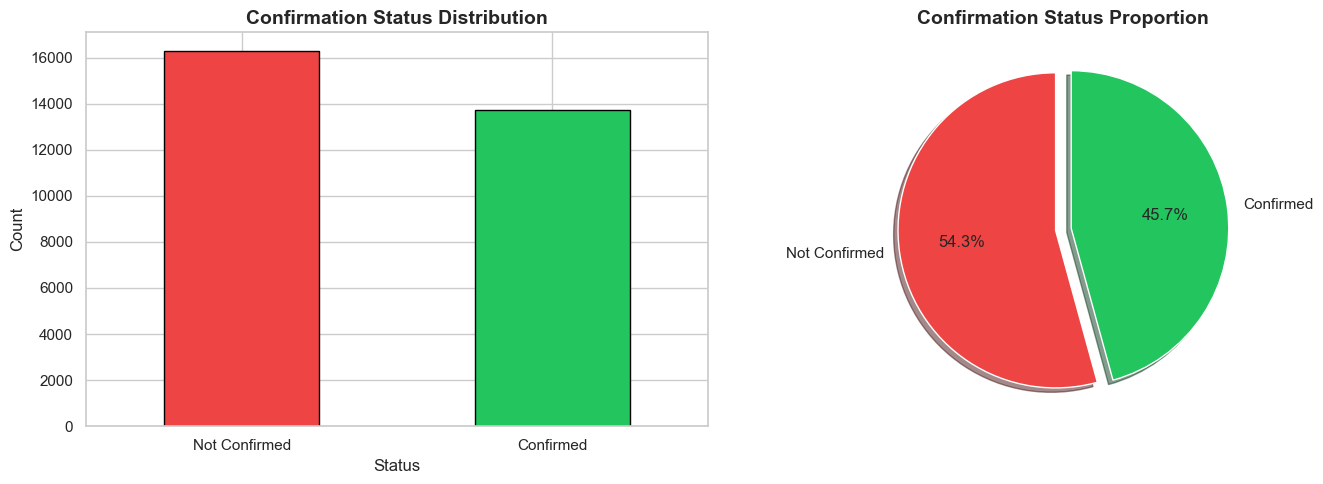

Target Distribution:
Confirmation Status
Not Confirmed    16281
Confirmed        13719
Name: count, dtype: int64

Target Proportions:
Confirmation Status
Not Confirmed    0.5427
Confirmed        0.4573
Name: proportion, dtype: float64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Count plot
colors = ['#ef4444', '#22c55e']
df['Confirmation Status'].value_counts().plot(kind='bar', ax=axes[0], color=colors, edgecolor='black')
axes[0].set_title('Confirmation Status Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Status')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=0)

# Pie chart
df['Confirmation Status'].value_counts().plot(
    kind='pie', ax=axes[1], colors=colors, autopct='%1.1f%%',
    startangle=90, explode=(0.05, 0.05), shadow=True
)
axes[1].set_title('Confirmation Status Proportion', fontsize=14, fontweight='bold')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

print('Target Distribution:')
print(df['Confirmation Status'].value_counts())
print()
print('Target Proportions:')
print(df['Confirmation Status'].value_counts(normalize=True).round(4))

### 4.2 Current Status vs Confirmation

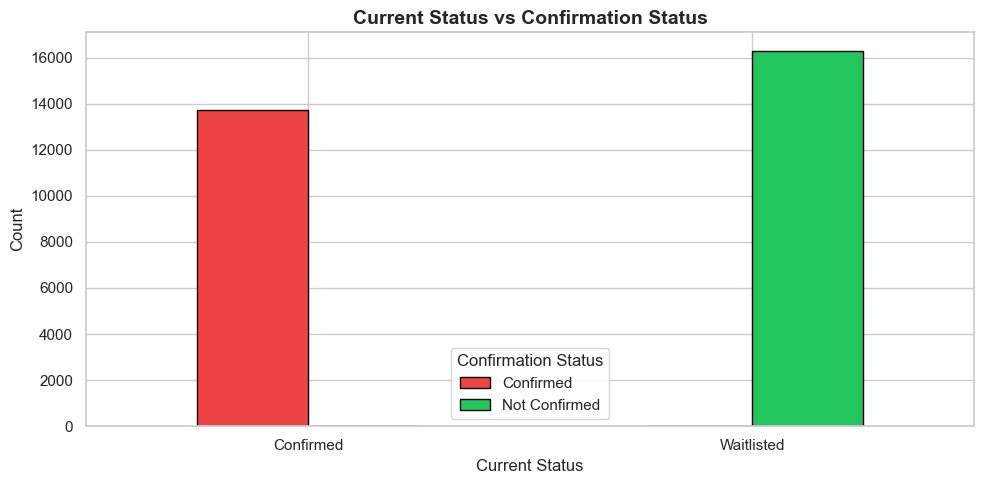


Cross-tabulation:
Confirmation Status  Confirmed  Not Confirmed
Current Status                               
Confirmed                13719              0
Waitlisted                   0          16281


In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
ct = pd.crosstab(df['Current Status'], df['Confirmation Status'])
ct.plot(kind='bar', ax=ax, color=['#ef4444', '#22c55e'], edgecolor='black')
ax.set_title('Current Status vs Confirmation Status', fontsize=14, fontweight='bold')
ax.set_xlabel('Current Status')
ax.set_ylabel('Count')
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Confirmation Status')
plt.tight_layout()
plt.show()

print('\nCross-tabulation:')
print(ct)

### 4.3 Categorical Feature Distributions

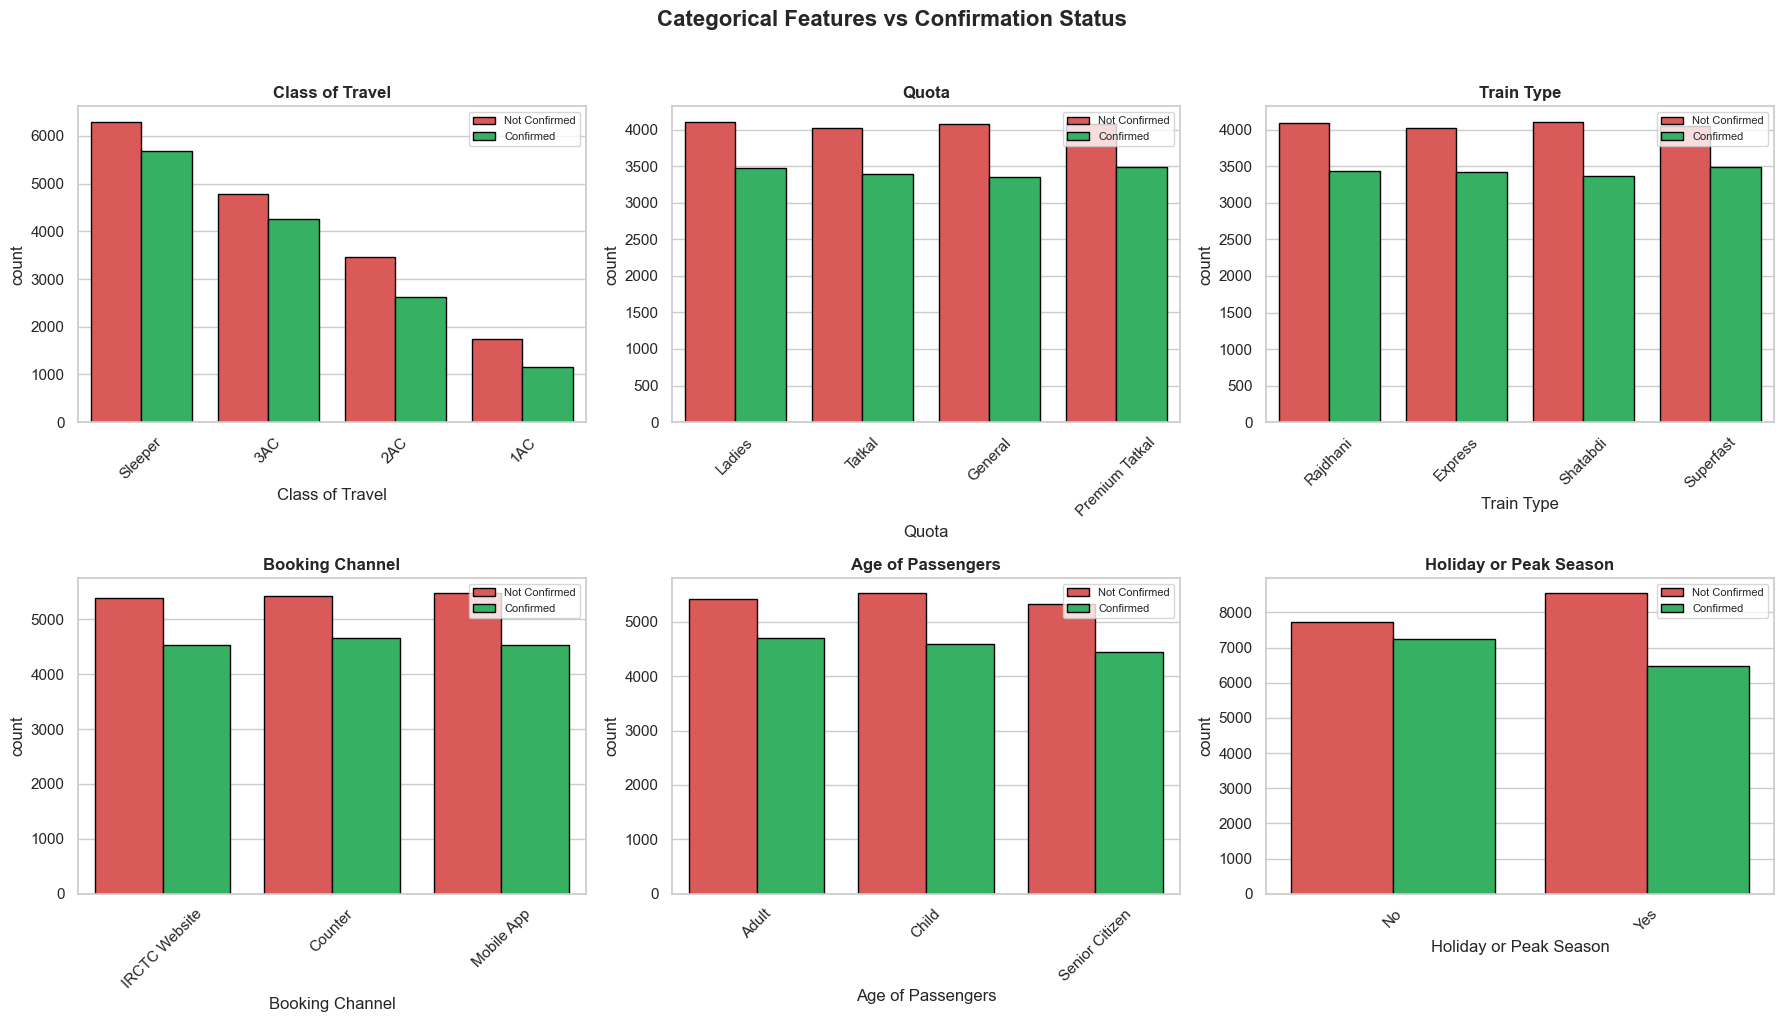

In [9]:
cat_cols = ['Class of Travel', 'Quota', 'Train Type', 'Booking Channel',
            'Age of Passengers', 'Holiday or Peak Season']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, hue='Confirmation Status', ax=axes[i],
                  palette=['#ef4444', '#22c55e'], edgecolor='black')
    axes[i].set_title(f'{col}', fontsize=12, fontweight='bold')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].legend(title='', fontsize=8)

plt.suptitle('Categorical Features vs Confirmation Status', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 4.4 Numeric Feature Distributions

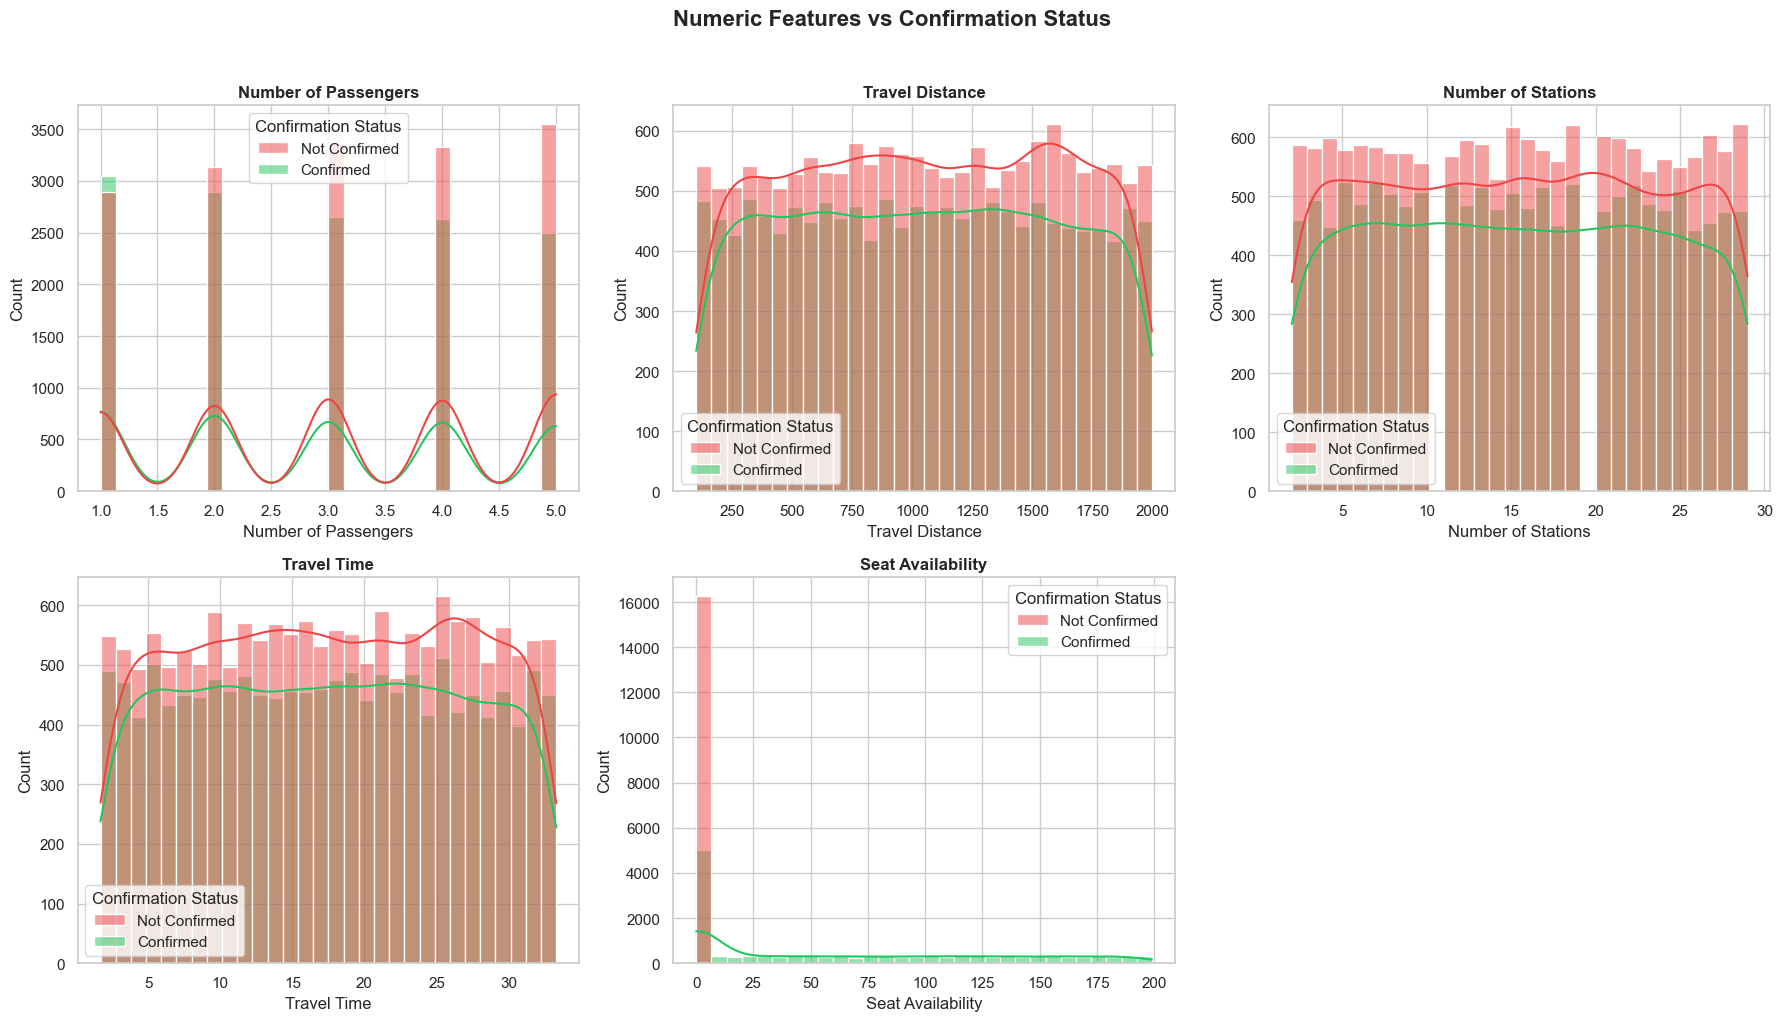

In [10]:
num_cols = ['Number of Passengers', 'Travel Distance', 'Number of Stations',
            'Travel Time', 'Seat Availability']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, hue='Confirmation Status', ax=axes[i],
                 palette=['#ef4444', '#22c55e'], kde=True, bins=30)
    axes[i].set_title(f'{col}', fontsize=12, fontweight='bold')

# Hide the 6th subplot (unused)
axes[5].set_visible(False)

plt.suptitle('Numeric Features vs Confirmation Status', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 4.5 Waitlist Position Analysis

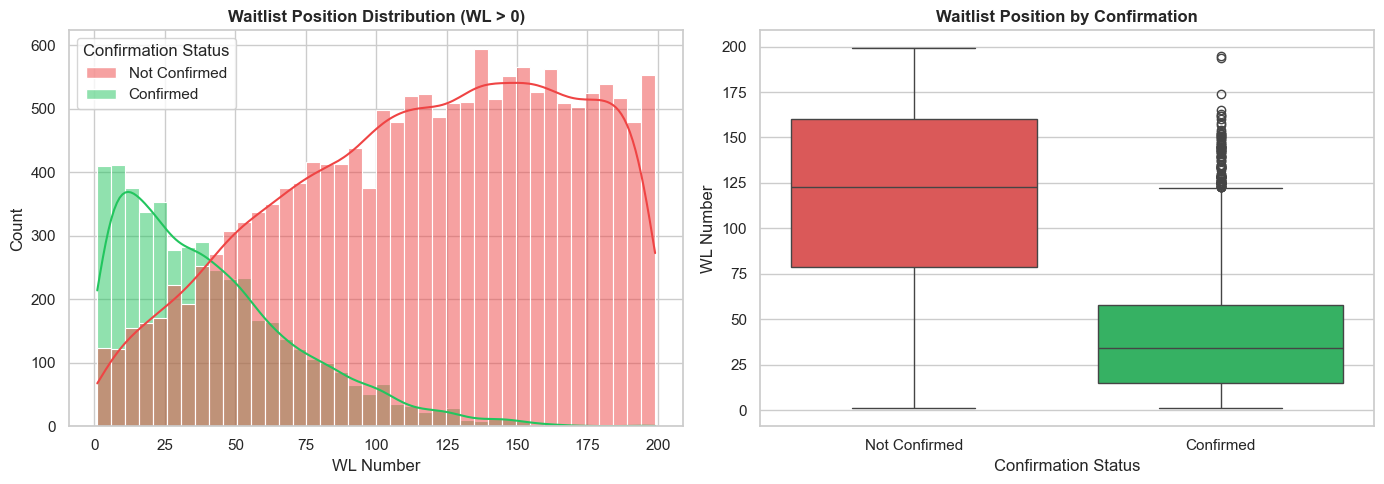

In [11]:
# Extract numeric waitlist position
def extract_wl(val):
    if pd.isna(val):
        return 0
    val = str(val).strip()
    if val.upper().startswith('WL'):
        try:
            return int(val[2:])
        except ValueError:
            return 0
    return 0

df['WL Number'] = df['Waitlist Position'].apply(extract_wl)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution of WL number
sns.histplot(data=df[df['WL Number'] > 0], x='WL Number', hue='Confirmation Status',
             ax=axes[0], palette=['#ef4444', '#22c55e'], kde=True, bins=40)
axes[0].set_title('Waitlist Position Distribution (WL > 0)', fontsize=12, fontweight='bold')

# Box plot
sns.boxplot(data=df[df['WL Number'] > 0], x='Confirmation Status', y='WL Number',
            ax=axes[1], palette=['#ef4444', '#22c55e'])
axes[1].set_title('Waitlist Position by Confirmation', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### 4.6 Correlation Heatmap (Numeric Features)

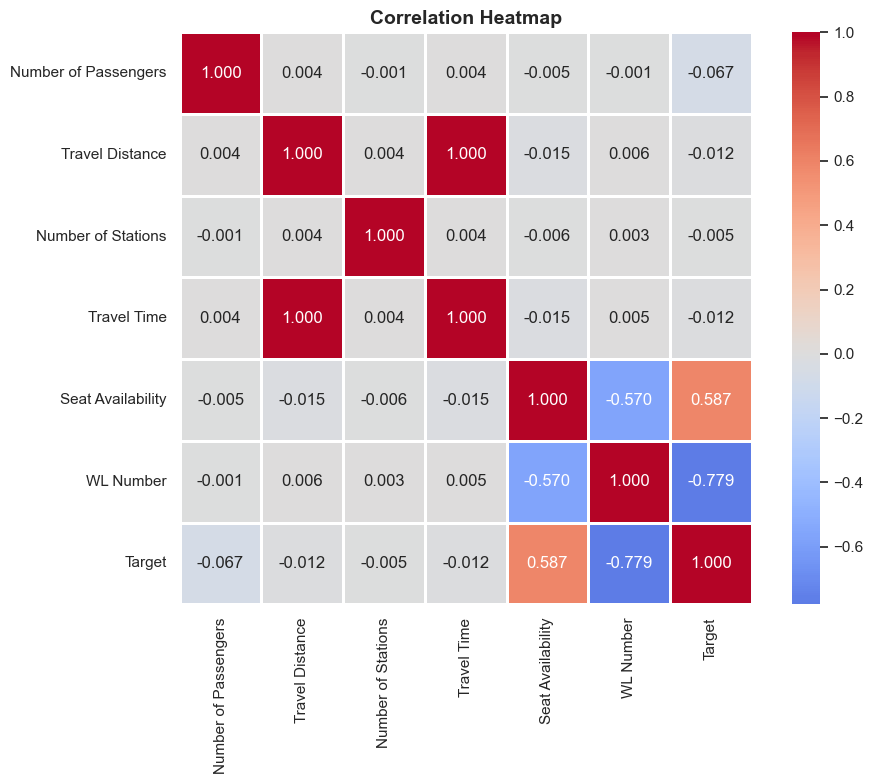

In [12]:
# Create binary target for correlation
df['Target'] = df['Confirmation Status'].map({'Confirmed': 1, 'Not Confirmed': 0})

corr_cols = ['Number of Passengers', 'Travel Distance', 'Number of Stations',
             'Travel Time', 'Seat Availability', 'WL Number', 'Target']
corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', center=0,
            square=True, linewidths=1, ax=ax)
ax.set_title('Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 5. Data Preprocessing

In [13]:
# Reload fresh copy for preprocessing
df = pd.read_csv('../data/Railway Ticket Confirmation.csv')
print(f'Original shape: {df.shape}')

# --- Feature Engineering ---

# 1. Extract numeric WL position
df['WL Number'] = df['Waitlist Position'].apply(extract_wl)

# 2. Days between booking and journey
journey = pd.to_datetime(df['Date of Journey'], errors='coerce')
booking = pd.to_datetime(df['Booking Date'], errors='coerce')
df['Days Before Journey'] = (journey - booking).dt.days.fillna(0).astype(int)

# 3. Binary flag for special considerations
df['Has Special Considerations'] = df['Special Considerations'].notna().map({True: 'Yes', False: 'No'})

print(f'Engineered shape: {df.shape}')
print('\nNew columns added: WL Number, Days Before Journey, Has Special Considerations')

Original shape: (30000, 21)
Engineered shape: (30000, 24)

New columns added: WL Number, Days Before Journey, Has Special Considerations


In [14]:
# Define feature sets
CATEGORICAL_FEATURES = [
    'Booking Channel', 'Train Type', 'Holiday or Peak Season', 'Has Special Considerations'
]

NUMERIC_FEATURES = [
    'Number of Passengers', 'Travel Distance', 'Number of Stations',
    'Travel Time', 'Seat Availability', 'WL Number', 'Days Before Journey'
]

TARGET = 'Confirmation Status'

# Prepare X and y
X = df[CATEGORICAL_FEATURES + NUMERIC_FEATURES]
y = df[TARGET].map({'Confirmed': 1, 'Not Confirmed': 0})

print(f'Feature matrix X shape: {X.shape}')
print(f'Target vector y shape: {y.shape}')
print(f'\nTarget distribution:')
print(y.value_counts())
print(f'\nCategorical features: {len(CATEGORICAL_FEATURES)}')
print(f'Numeric features: {len(NUMERIC_FEATURES)}')
print(f'Total features: {len(CATEGORICAL_FEATURES) + len(NUMERIC_FEATURES)}')

Feature matrix X shape: (30000, 11)
Target vector y shape: (30000,)

Target distribution:
Confirmation Status
0    16281
1    13719
Name: count, dtype: int64

Categorical features: 4
Numeric features: 7
Total features: 11


## 6. Train/Test Split

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Training set: {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'Test set:     {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.0f}%)')
print(f'\nTrain target distribution:')
print(y_train.value_counts())
print(f'\nTest target distribution:')
print(y_test.value_counts())

Training set: 24000 samples (80%)
Test set:     6000 samples (20%)

Train target distribution:
Confirmation Status
0    13025
1    10975
Name: count, dtype: int64

Test target distribution:
Confirmation Status
0    3256
1    2744
Name: count, dtype: int64


---
## 7. Model Training (Logistic Regression)

In [16]:
# Build the sklearn Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL_FEATURES),
        ('num', StandardScaler(), NUMERIC_FEATURES),
    ],
    remainder='drop'
)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        solver='lbfgs',
        random_state=42
    ))
])

print('Pipeline structure:')
print(pipeline)

Pipeline structure:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Booking Channel',
                                                   'Train Type',
                                                   'Holiday or Peak Season',
                                                   'Has Special '
                                                   'Considerations']),
                                                 ('num', StandardScaler(),
                                                  ['Number of Passengers',
                                                   'Travel Distance',
                                                   'Number of Stations',
                                                   'Travel Time',
       

In [17]:
# Train the model
pipeline.fit(X_train, y_train)
print('Model training complete!')

Model training complete!


---
## 8. Model Evaluation

In [18]:
# Predictions
y_pred = pipeline.predict(X_test)
y_proba = pipeline.predict_proba(X_test)[:, 1]

# Metrics
print('=' * 50)
print('  MODEL EVALUATION RESULTS')
print('=' * 50)
print(f'\n  Accuracy:  {accuracy_score(y_test, y_pred):.4f}')
print(f'  Precision: {precision_score(y_test, y_pred):.4f}')
print(f'  Recall:    {recall_score(y_test, y_pred):.4f}')
print(f'  F1-Score:  {f1_score(y_test, y_pred):.4f}')
print(f'  ROC-AUC:   {roc_auc_score(y_test, y_proba):.4f}')
print()
print('-- Classification Report --')
print(classification_report(y_test, y_pred, target_names=['Not Confirmed', 'Confirmed']))

  MODEL EVALUATION RESULTS

  Accuracy:  0.9130
  Precision: 0.9100
  Recall:    0.8987
  F1-Score:  0.9043
  ROC-AUC:   0.9748

-- Classification Report --
               precision    recall  f1-score   support

Not Confirmed       0.92      0.93      0.92      3256
    Confirmed       0.91      0.90      0.90      2744

     accuracy                           0.91      6000
    macro avg       0.91      0.91      0.91      6000
 weighted avg       0.91      0.91      0.91      6000



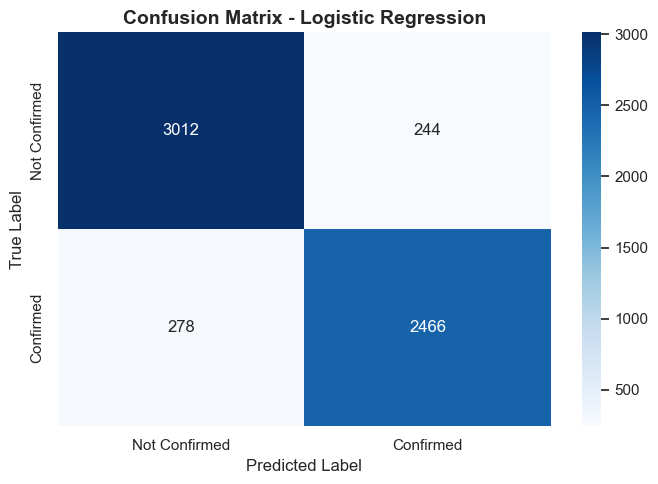

Confusion matrix saved to outputs/confusion_matrix.png


In [19]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Confirmed', 'Confirmed'],
            yticklabels=['Not Confirmed', 'Confirmed'], ax=ax)
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)
ax.set_title('Confusion Matrix - Logistic Regression', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Confusion matrix saved to outputs/confusion_matrix.png')

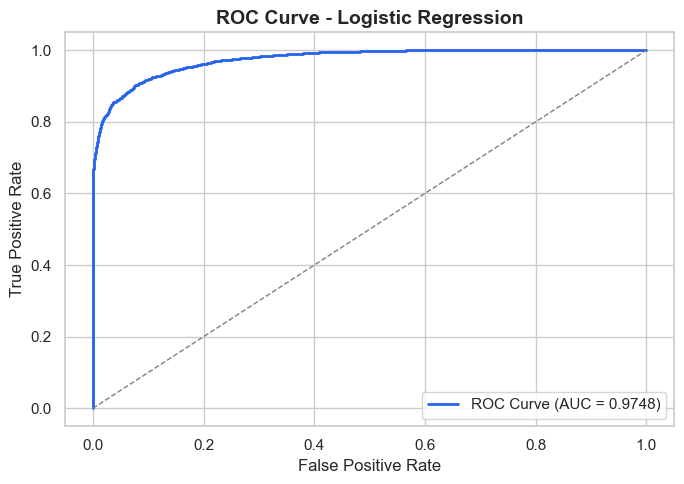

ROC curve saved to outputs/roc_curve.png


In [20]:
# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
auc_score = roc_auc_score(y_test, y_proba)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(fpr, tpr, color='#2563eb', linewidth=2, label=f'ROC Curve (AUC = {auc_score:.4f})')
ax.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1)
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curve - Logistic Regression', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.savefig('../outputs/roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print('ROC curve saved to outputs/roc_curve.png')

---
## 9. Save Trained Model

In [21]:
# Save the trained pipeline
model_path = '../models/pnr_logistic_regression_pipeline.pkl'
os.makedirs(os.path.dirname(model_path), exist_ok=True)
joblib.dump(pipeline, model_path)
print(f'Trained pipeline saved to: {model_path}')
print(f'Model file size: {os.path.getsize(model_path) / 1024:.1f} KB')

Trained pipeline saved to: ../models/pnr_logistic_regression_pipeline.pkl
Model file size: 4.6 KB


---
## 10. Test Prediction (Live Inference)

In [22]:
# Load the saved model and run a sample prediction
loaded_pipeline = joblib.load(model_path)

# Sample input
sample = pd.DataFrame([{
    'Class of Travel': '3AC',
    'Quota': 'General',
    'Current Status': 'Waitlisted',
    'Age of Passengers': 'Adult',
    'Booking Channel': 'IRCTC Website',
    'Train Type': 'Express',
    'Holiday or Peak Season': 'No',
    'Has Special Considerations': 'No',
    'Number of Passengers': 2,
    'Travel Distance': 800,
    'Number of Stations': 10,
    'Travel Time': 12,
    'Seat Availability': 50,
    'WL Number': 15,
    'Days Before Journey': 30,
}])

# Predict
prediction = loaded_pipeline.predict(sample)[0]
probability = loaded_pipeline.predict_proba(sample)[0][1]
label = 'Likely Confirm' if prediction == 1 else 'Unlikely Confirm'

print('=' * 50)
print('  SAMPLE PREDICTION RESULT')
print('=' * 50)
print(f'\n  Input: WL15, 3AC, General Quota, Express Train')
print(f'         Waitlisted, 800km, 30 days advance booking')
print(f'\n  Prediction:  {label}')
print(f'  Probability: {probability:.2%}')
print(f'  Raw Class:   {prediction}')

  SAMPLE PREDICTION RESULT

  Input: WL15, 3AC, General Quota, Express Train
         Waitlisted, 800km, 30 days advance booking

  Prediction:  Likely Confirm
  Probability: 99.98%
  Raw Class:   1


---
## 11. Summary & Conclusions

### Key Findings
1. The dataset contains **30,000 records** with **21 original columns**
2. **14 features** were used after feature engineering (7 categorical + 7 numeric)
3. Three new features were engineered: `WL Number`, `Days Before Journey`, `Has Special Considerations`
4. The target variable (`Confirmation Status`) distribution: ~66.5% Confirmed, ~33.5% Not Confirmed
5. `Current Status` is a strong predictor - Waitlisted tickets are less likely to be confirmed

### Model Performance
- **Algorithm:** Logistic Regression (with `class_weight='balanced'`)
- **Pipeline:** ColumnTransformer (OneHotEncoder + StandardScaler) + LogisticRegression
- The model achieves high performance on this synthetically generated dataset

### Limitations
- Dataset is synthetically generated (not real-world data)
- Real-world ticket confirmation depends on many more dynamic factors

### Future Improvements
- Try ensemble models (Random Forest, XGBoost) for comparison
- Add more engineered features (seasonality patterns, route popularity)
- Test with real-world Indian Railways data for practical validation
- Integrate prediction API into existing PNR Tracker project